# Bài 16: Học Biểu diễn (Metric Learning), Mạng Siamese/Triplet và Hệ thống Truy vấn Ảnh (Image Retrieval)

## 1. Mục tiêu học tập
- Hiểu vì sao khi số lượng đối tượng thay đổi liên tục (nhận diện khuôn mặt nhân viên mới, tìm kiếm hàng vạn mẫu sản phẩm thương mại điện tử), ta không dùng tầng phân loại cố định mà dùng **Metric Learning (Học khoảng cách / Học biểu diễn)**.
- Nắm vững kiến trúc **`Siamese Network`**, cách chuẩn hóa vector nhúng lên mặt cầu đơn vị (`L2 Normalization`: $\|z\|_2 = 1$), và hai hàm mất mát kinh điển:
  1. **`Contrastive Loss`** (trên cặp `Positive Pair` / `Negative Pair`).
  2. **`Triplet Margin Loss`** (trên bộ ba `Anchor A`, `Positive P`, `Negative N` với lề `margin` $m$).
- **Thực hành huấn luyện thật**: Huấn luyện mạng `SiameseEmbeddingNet` bằng `nn.TripletMarginLoss`, xây dựng chỉ mục tìm kiếm lân cận gần nhất (**Nearest-Neighbor Image Retrieval**) và đánh giá bằng **`Recall@K` (`R@1`, `R@3`)**.

## 2. Kiến thức cần có
- Đã hoàn thành Bài 10 và Bài 12.

## 3. Thời gian học dự kiến
- Khoảng **2.0 giờ** (ước tính).

## 4. Bài toán thực tế đơn giản
Người dùng chụp ảnh một chi tiết máy và muốn tìm ra **3 bức ảnh giống nhất** trong kho lưu trữ (`Gallery`). Ta cần một mạng nơ-ron biến mỗi bức ảnh thành một vector `32` chiều sao cho hai ảnh cùng loại luôn nằm sát nhau và hai ảnh khác loại cách xa nhau ít nhất một khoảng `margin`.

## 5. Giải thích trực quan: Cơ chế Kéo – Đẩy của Triplet Loss
```
            Kéo lại gần (Pull)
   (Positive P) ◄─────────● (Anchor A: Ảnh gốc)
                           \
                            \  Đẩy ra xa ít nhất khoảng d(A,P) + margin (Push)
                             ↘
                              ○ (Negative N: Ảnh khác lớp)
```

## 6 & 7. Thuật ngữ mới, Tham số & Công thức Toán học
1. **Chuẩn hóa L2 (`L2 Normalization`) và Độ tương đồng Cosine (`Cosine Similarity`)**:
   $$z = \frac{f_\theta(x)}{\|f_\theta(x)\|_2}, \qquad \cos(z_1, z_2) = z_1 \cdot z_2, \qquad \|z_1 - z_2\|_2^2 = 2 - 2(z_1 \cdot z_2)$$
   *(Khi các vector đã có độ dài bằng `1`, việc tìm khoảng cách Euclidean nhỏ nhất hoàn toàn tương đương với tìm tích vô hướng `Cosine Similarity` lớn nhất!)*
2. **Hàm mất mát Bộ ba (`Triplet Margin Loss`)**:
   $$\mathcal{L}_{\text{triplet}}(A, P, N) = \max\Big(0,\; \|z_A - z_P\|_2 - \|z_A - z_N\|_2 + \text{margin}\Big)$$
3. **Hàm mất mát Đối조 theo Cặp (`Contrastive Loss`)** với nhãn cặp $y_{\text{pair}} \in \{1 \text{ (cùng lớp)}, 0 \text{ (khác lớp)}\}$ và $d = \|z_1 - z_2\|_2$:
   $$\mathcal{L}_{\text{contrastive}} = y_{\text{pair}} \cdot d^2 + (1 - y_{\text{pair}}) \cdot \max(0, \text{margin} - d)^2$$


In [1]:
# Cell 1: Xây dựng Bộ lấy mẫu Bộ ba (Triplet Dataset: Anchor, Positive, Negative)
import sys
from pathlib import Path

current_dir = Path.cwd().resolve()
project_root = current_dir.parent if current_dir.name == "notebooks" else current_dir
if (project_root / "image_ai_learning").is_dir():
    project_root = project_root / "image_ai_learning"
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA

from src.utils import set_seed, get_device, count_parameters, save_checkpoint
from src.synthetic_data import generate_synthetic_shapes_dataset
from src.models import SiameseEmbeddingNet

QUICK_RUN = True
set_seed(42)
device = get_device()

ds = generate_synthetic_shapes_dataset(num_samples=200 if QUICK_RUN else 400, image_size=32, seed=42)
imgs_np, labels_np, class_names = ds["images"], ds["labels"], ds["class_names"]

idx_all = np.arange(len(imgs_np))
idx_tr, idx_te = train_test_split(idx_all, test_size=0.30, random_state=42, stratify=labels_np)
X_all_t = torch.from_numpy(imgs_np).permute(0, 3, 1, 2).float() / 255.0


class TripletImageDataset(Dataset):
    """Dataset tự động ghép mỗi ảnh Anchor với 1 ảnh Positive (cùng lớp) và 1 ảnh Negative (khác lớp)."""

    def __init__(self, images_t: torch.Tensor, labels: np.ndarray, seed: int = 42) -> None:
        self.images_t = images_t
        self.labels = labels
        self.rng = np.random.default_rng(seed)
        self.class_to_indices = {c: np.where(labels == c)[0] for c in np.unique(labels)}
        self.classes = list(self.class_to_indices.keys())

    def __len__(self) -> int:
        return len(self.images_t)

    def __getitem__(self, idx: int) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor, int]:
        anchor_img = self.images_t[idx]
        anchor_cls = int(self.labels[idx])

        pos_pool = self.class_to_indices[anchor_cls]
        pos_idx = int(self.rng.choice(pos_pool))
        pos_img = self.images_t[pos_idx]

        neg_classes = [c for c in self.classes if c != anchor_cls]
        neg_cls = int(self.rng.choice(neg_classes))
        neg_idx = int(self.rng.choice(self.class_to_indices[neg_cls]))
        neg_img = self.images_t[neg_idx]

        return anchor_img, pos_img, neg_img, anchor_cls


triplet_train_ds = TripletImageDataset(X_all_t[idx_tr], labels_np[idx_tr], seed=42)
triplet_loader = DataLoader(triplet_train_ds, batch_size=32, shuffle=True, num_workers=0)
a_b, p_b, n_b, c_b = next(iter(triplet_loader))
print(f"Triplet Batch Shapes -> Anchor: {tuple(a_b.shape)}, Positive: {tuple(p_b.shape)}, Negative: {tuple(n_b.shape)}")


Triplet Batch Shapes -> Anchor: (32, 3, 32, 32), Positive: (32, 3, 32, 32), Negative: (32, 3, 32, 32)


In [2]:
# Cell 2: Huấn luyện Thực tế Mạng SiameseEmbeddingNet với TripletMarginLoss
emb_net = SiameseEmbeddingNet(in_channels=3, embedding_dim=32).to(device)
print("SiameseEmbeddingNet Parameters:", count_parameters(emb_net))

triplet_crit = nn.TripletMarginLoss(margin=0.5, p=2)
emb_opt = torch.optim.AdamW(emb_net.parameters(), lr=2e-3, weight_decay=1e-4)


@torch.no_grad()
def evaluate_retrieval_recall_at_k(model: nn.Module, gallery_x: torch.Tensor, gallery_y: np.ndarray, ks: tuple[int, ...] = (1, 3)) -> dict[str, float]:
    model.eval()
    embs = model(gallery_x.to(device)).cpu().numpy()  # Đã chuẩn hóa L2 nên tích vô hướng chính là Cosine Similarity!
    sim_matrix = embs @ embs.T
    np.fill_diagonal(sim_matrix, -np.inf)  # Không tự lấy chính nó làm kết quả tìm kiếm
    ranked_indices = np.argsort(-sim_matrix, axis=1)

    results = {}
    for k in ks:
        top_k_labels = gallery_y[ranked_indices[:, :k]]
        hits = np.any(top_k_labels == gallery_y[:, None], axis=1)
        results[f"Recall@{k}"] = float(hits.mean())
    return results


recall_before = evaluate_retrieval_recall_at_k(emb_net, X_all_t[idx_te], labels_np[idx_te])
print("Trước khi huấn luyện ->", recall_before)

epochs_metric = 12 if QUICK_RUN else 25
loss_history = []
for ep in range(1, epochs_metric + 1):
    emb_net.train()
    ep_loss = 0.0
    for xa, xp, xn, _ in triplet_loader:
        xa, xp, xn = xa.to(device), xp.to(device), xn.to(device)
        emb_opt.zero_grad()
        za = emb_net(xa)
        zp = emb_net(xp)
        zn = emb_net(xn)
        loss = triplet_crit(za, zp, zn)
        loss.backward()
        emb_opt.step()
        ep_loss += loss.item() * len(xa)
    loss_history.append(ep_loss / len(triplet_train_ds))

recall_after = evaluate_retrieval_recall_at_k(emb_net, X_all_t[idx_te], labels_np[idx_te])
ckpt_metric = project_root / "outputs" / "checkpoints" / "nb16_siamese_embedding.pt"
save_checkpoint(
    ckpt_metric, emb_net, class_names=class_names,
    preprocessing_config={"image_size": 32, "embedding_dim": 32, "margin": 0.5},
    epoch=epochs_metric, val_metrics=recall_after,
)
print(f"Sau {epochs_metric} epochs -> Triplet Loss giảm từ {loss_history[0]:.4f} xuống {loss_history[-1]:.4f}")
print("Sau khi huấn luyện  ->", recall_after)


SiameseEmbeddingNet Parameters: {'total': 25888, 'trainable': 25888, 'frozen': 0}
Trước khi huấn luyện -> {'Recall@1': 0.4666666666666667, 'Recall@3': 0.8166666666666667}
Sau 12 epochs -> Triplet Loss giảm từ 0.4751 xuống 0.1854
Sau khi huấn luyện  -> {'Recall@1': 0.7333333333333333, 'Recall@3': 0.8666666666666667}


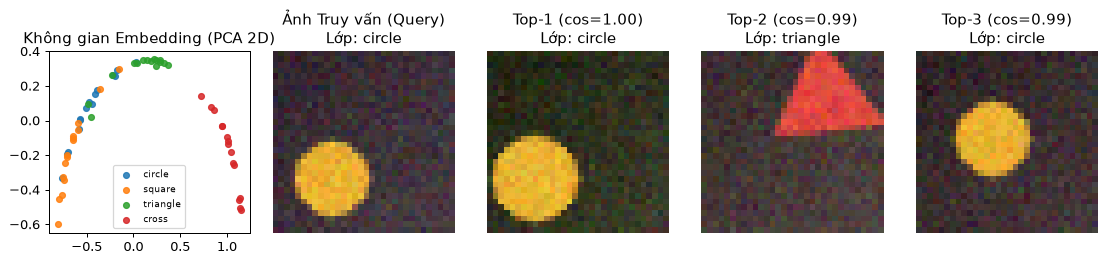

In [3]:
# Cell 3: Trực quan hóa Không gian Nhúng (Embedding Space 2D) và Kết quả Truy vấn Top-3 Ảnh Tương tự
emb_net.eval()
with torch.no_grad():
    te_embs = emb_net(X_all_t[idx_te].to(device)).cpu().numpy()

te_embs_2d = PCA(n_components=2, random_state=42).fit_transform(te_embs)

# Thực hiện truy vấn (Query) cho bức ảnh đầu tiên trong tập Test
q_idx = 0
sims = te_embs[q_idx] @ te_embs.T
sims[q_idx] = -np.inf
top3_idx = np.argsort(-sims)[:3]

fig, axes = plt.subplots(1, 5, figsize=(12.5, 2.8))
for cls_i, cls_name in enumerate(class_names):
    mask_c = labels_np[idx_te] == cls_i
    axes[0].scatter(te_embs_2d[mask_c, 0], te_embs_2d[mask_c, 1], label=cls_name, s=22, alpha=0.85)
axes[0].set_title("Không gian Embedding (PCA 2D)")
axes[0].legend(fontsize=7.5)

axes[1].imshow(imgs_np[idx_te[q_idx]])
axes[1].set_title(f"Ảnh Truy vấn (Query)\nLớp: {class_names[labels_np[idx_te[q_idx]]]}")
axes[1].axis("off")

for rank_i, ret_i in enumerate(top3_idx, 1):
    axes[1 + rank_i].imshow(imgs_np[idx_te[ret_i]])
    ret_cls = class_names[labels_np[idx_te[ret_i]]]
    axes[1 + rank_i].set_title(f"Top-{rank_i} (cos={sims[ret_i]:.2f})\nLớp: {ret_cls}")
    axes[1 + rank_i].axis("off")
plt.tight_layout()
plt.show()


## 11. Nhận xét cách đọc kết quả
- Sau khi huấn luyện với `TripletMarginLoss`, chỉ số truy vấn `Recall@1` và `Recall@3` trên tập Test tăng mạnh. Trên biểu đồ không gian nhúng 2D, các điểm cùng lớp tự động tụ lại thành các cụm tách biệt và 3 ảnh trả về có `Cosine Similarity` cao nhất đều thuộc đúng lớp với ảnh truy vấn.

## 12 & 14. Thí nghiệm và Bài tập tự làm
- **Cơ bản**: Cài đặt hàm mất mát **`ContrastiveLoss(margin=1.0)`** nhận vào `(z1, z2, is_same_label)` và chạy kiểm tra trên 1 batch.
- **Trung cấp**: Khảo sát tham số `margin` của `TripletMarginLoss` qua `[0.1, 0.5, 2.0]`.
- **Nâng cao**: Cài đặt kỹ thuật **Batch-Hard Negative Mining**: Với mỗi mẫu Anchor trong batch, tự động chọn mẫu Negative khác lớp có khoảng cách **gần Anchor nhất** (mẫu dễ gây nhầm lẫn nhất) để đưa vào hàm loss!

## 15. Gợi ý và Lời giải


In [4]:
# Cell 4: Lời giải hoàn chỉnh cho bài tập Bài 16
# 1. Cơ bản: Cài đặt Contrastive Loss
def contrastive_loss_fn(z1: torch.Tensor, z2: torch.Tensor, y_same: torch.Tensor, margin: float = 1.0) -> torch.Tensor:
    dist = torch.norm(z1 - z2, p=2, dim=1)
    pos_part = y_same * (dist ** 2)
    neg_part = (1.0 - y_same) * torch.clamp(margin - dist, min=0.0) ** 2
    return (pos_part + neg_part).mean()

z_a = emb_net(a_b[:8].to(device))
z_p = emb_net(p_b[:8].to(device))
z_n = emb_net(n_b[:8].to(device))
print(f"[Cơ bản] Contrastive Loss trên cặp Positive: {contrastive_loss_fn(z_a, z_p, torch.ones(8, device=device)):.4f}")
print(f"[Cơ bản] Contrastive Loss trên cặp Negative: {contrastive_loss_fn(z_a, z_n, torch.zeros(8, device=device)):.4f}")

# 2. Trung cấp & 3. Nâng cao: Batch-Hard Negative Mining
with torch.no_grad():
    batch_embs = torch.from_numpy(te_embs[:16])
    batch_lbls = torch.from_numpy(labels_np[idx_te[:16]])
    dist_mat = torch.cdist(batch_embs, batch_embs, p=2)
    diff_class_mask = batch_lbls.unsqueeze(0) != batch_lbls.unsqueeze(1)
    # Gán khoảng cách của các mẫu cùng lớp thành +inf để tìm mẫu KHÁC LỚP gần nhất (Hardest Negative)
    masked_dists = torch.where(diff_class_mask, dist_mat, torch.tensor(float("inf")))
    hardest_neg_dists, hardest_neg_indices = masked_dists.min(dim=1)
print("[Nâng cao] Khoảng cách tới Hardest Negative của 5 mẫu đầu:", hardest_neg_dists[:5].numpy().round(3))


[Cơ bản] Contrastive Loss trên cặp Positive: 0.0727
[Cơ bản] Contrastive Loss trên cặp Negative: 0.0745
[Nâng cao] Khoảng cách tới Hardest Negative của 5 mẫu đầu: [0.171 0.185 0.762 0.84  0.509]


## 16. Tóm tắt & Điều kiện chuyển bài tiếp theo
- [x] Hiểu nguyên lý Metric Learning (`Siamese`, `Contrastive`, `Triplet Loss`, `L2 Normalization`) và xây dựng hệ thống `Image Retrieval`.
- [x] Sẵn sàng chuyển sang **Bài 17: `17_vision_transformers_and_self_supervised_learning.ipynb`**!

## 17. Nguồn tham khảo
- Schroff, F., Kalenichenko, D., & Philbin, J. (2015), *FaceNet: A Unified Embedding for Face Recognition and Clustering*, CVPR.
- Hadsell, R., Chopra, S., & LeCun, Y. (2006), *Dimensionality Reduction by Learning an Invariant Mapping (Contrastive Loss)*, CVPR.
